## Proyecto final: Clasificación de señales ECG 
## Proyecto 2026-02 


## Presentado por:

 Esteban Garcia Otalvaro
 
 Fabian Andres Posso

Bioseñales y Sistemas — Bioingeniería, Universidad de Antioquia — 2026-02

Base de datos: Chapman University & Shaoxing People's Hospital (Zheng et al., 2020), disponible en Figshare: https://figshare.com/collections/ChapmanECG/4560497/1 [1]

In [57]:
# Importa el módulo os para interactuar con el sistema operativo y manejar rutas de archivos
import os, glob, zipfile

# Importa seaborn (como sns) para generar gráficas estadísticas y visualizaciones más atractivas
import seaborn as sns

# Importa numpy (como np) para realizar cálculos numéricos y manejar arreglos matemáticos
import numpy as np

# Importa pandas (como pd) para cargar, leer y manipular el archivo Excel como una tabla de datos (DataFrame)
import pandas as pd

# Importa el submódulo pyplot de matplotlib para generar gráficas visuales
import matplotlib.pyplot as plt

# Importa FancyBboxPatch para poder dibujar cajas con bordes redondeados dentro de las gráficas
from matplotlib.patches import FancyBboxPatch

# Importa las pruebas estadísticas de Chi-cuadrado y Fisher para analizar cruces de variables categóricas (ej. Género vs Arritmia)
from scipy.stats import chi2_contingency, fisher_exact

# Importa la prueba de Kruskal-Wallis (para comparar medianas) y skew (para calcular la asimetría de los datos)
from scipy.stats import kruskal, skew

# Importa la distribución Chi-cuadrado y la renombra como dist_chi2 para que no haga conflicto con otros nombres
from scipy.stats import chi2 as dist_chi2

# Importa la función iqr (rango intercuartílico) de scipy.stats para calcular la dispersión de los datos
from scipy.stats import kruskal, chi2_contingency, iqr

import pandas as pd
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)

## 1.Revisión teórica del artículo "optimal Multi-Stage Arrhythmia Classification Approach"




Enlace de acceso artículo 1: https://www.nature.com/articles/s41598-020-59821-7

**Resumen de la sección "Extracción de caracteristicas[2]:**

La idea central es que, en lugar de buscar y medir cada onda del latido (P, Q, R, S, T), los autores miden todos los picos y valles de la señal sin preocuparse por qué onda es cada uno, y resumen esas medidas en histogramas. Así el método sigue funcionando aunque falte alguna onda.

A continuación se explican las razones de no usar las herramientas alternativas:

• Medir cada onda por separado (su altura, su duración, la distancia entre ellas) falla en las arritmias donde esas ondas se deforman o desaparecen.

• Redes neuronales que aprenden las características solas necesitan muchos datos y mucho cómputo, y no se puede saber qué está midiendo la red.

• Fourier o wavelets indican qué frecuencias hay, pero no cuándo ocurren.

A continuación se explica el paso a paso del método propuesto, que es interpretable y se aplica a la derivación II:

**1.  Reescalado.** Cada señal se normaliza por máximo–mínimo para que su pico máximo sea 1. Con esto se compensan las diferencias de amplitud entre personas (sexo, edad, raza). El efecto sobre la clasificación es pequeño pero positivo: el F1 sube entre 0,001 y 0,0016.

**2.  Picos y valles.** Se toman todos los máximos y mínimos locales de la señal filtrada. De cada uno se miden la altura, el ancho y la prominencia, que es la distancia vertical entre el pico y su línea de contorno más baja.

**3.  Tres subconjuntos.** Cada pico o valle se asigna a uno de tres grupos: complejos QRS, picos que no son QRS y valles.

**4.  Seis combinaciones por pares.** Se comparan los elementos de a dos: QRS–QRS, no-QRS–no-QRS, valle–valle, QRS–no-QRS, QRS–valle y no-QRS–valle. Para cada par se calcula la diferencia de ubicación en el tiempo y tres cocientes: diferencia de ancho, de altura y de prominencia, cada una dividida por la diferencia de tiempo.

**5.  Vector de longitud fija.** Cada paciente tiene un número distinto de picos y de cocientes, así que no se pueden usar directamente. Por eso se construye una tabla de frecuencias empírica con 100 clases entre el mínimo y el máximo de cada variable (Figs. 15–17 del artículo).

**6.  Características adicionales.** Se agregan la edad, el sexo, la media y la varianza de los intervalos RR, el número de intervalos RR y las mediciones del equipo: frecuencia ventricular y auricular, duración del QRS, intervalo QT, eje R, eje T, conteo de QRS y los inicios y finales de la onda Q.

**Resultado.** Con las mismas condiciones, los modelos con las características diseñadas en la derivación II (Grupo 2) obtienen un F1 promedio 0,021 mayor que los que usan solo las mediciones del equipo (Grupo 1).

**Cómo se arma el vector de características**

El Grupo 6 (solo derivación II) es el que concentra las 3.302 variables del artículo. Cada bloque son histogramas de 100 clases:

In [13]:
N_CLASES = 100                      # clases de cada histograma
N_ATRIBUTOS = 3                     # altura, ancho y prominencia
N_SUBCONJUNTOS = 3                  # QRS, picos no-QRS y valles
N_PARES = 6                         # QRS-QRS, noQRS-noQRS, valle-valle, QRS-noQRS, QRS-valle, noQRS-valle
N_COCIENTES = 3                     # altura/tiempo, ancho/tiempo, prominencia/tiempo

tabla_grupo6 = pd.DataFrame([
    ['Altura, ancho y prominencia de QRS, picos no-QRS y valles',
     '3 atributos × 3 subconjuntos × 100 clases', N_ATRIBUTOS * N_SUBCONJUNTOS * N_CLASES],
    ['Diferencia de ubicación entre pares',
     '6 combinaciones × 100 clases', N_PARES * N_CLASES],
    ['Cocientes (altura, ancho y prominencia sobre diferencia de tiempo)',
     '3 cocientes × 6 combinaciones × 100 clases', N_COCIENTES * N_PARES * N_CLASES],
    ['Edad y sexo (deducido: 3.302 − 3.300)', '2 variables', 2],
], columns=['Bloque', 'Cuenta', 'Variables'])

total = tabla_grupo6['Variables'].sum()
tabla_grupo6.loc[len(tabla_grupo6)] = ['Total', '', total]
assert total == 3302, "El total debe coincidir con el Grupo 6 del artículo (3.302)"
tabla_grupo6

def centrar(df):
    return (df.style
              .set_properties(**{'text-align': 'center'})
              .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center')]}])
              .hide(axis='index'))
    
display(centrar(tabla_grupo6))

Bloque,Cuenta,Variables
"Altura, ancho y prominencia de QRS, picos no-QRS y valles",3 atributos × 3 subconjuntos × 100 clases,900
Diferencia de ubicación entre pares,6 combinaciones × 100 clases,600
"Cocientes (altura, ancho y prominencia sobre diferencia de tiempo)",3 cocientes × 6 combinaciones × 100 clases,1800
Edad y sexo (deducido: 3.302 − 3.300),2 variables,2
Total,,3302


La siguiente tabla incluye todos los grupos de caracteristicas del artículo (cada grupo que se pudo formar es una mezcla de los bloques de medición del equipo, estadisticas simples e histogramas de la primera tabla) [1]:

In [14]:
tabla_grupos = pd.DataFrame({
    'Grupo': range(1, 12),
    'Contenido': [
        'Mediciones del equipo (frecuencia ventricular y auricular, duración QRS, QT, ejes R y T, conteo QRS, inicio y fin de Q)',
        'Media y varianza de RR, nº de intervalos RR, media y varianza de altura, ancho y prominencia de QRS, picos no-QRS y valles (derivación II)',
        'Grupo 1 + Grupo 2',
        'Grupo 2 ampliado a las 12 derivaciones',
        'Grupo 1 + Grupo 4',
        'Histogramas de la derivación II (Tabla 1)',
        'Grupo 2 + Grupo 6',
        'Grupos 1 + 2 + 6',
        'Grupo 6 en las 12 derivaciones',
        'Grupo 4 + Grupo 9',
        'Grupo 3 + Grupo 9',
    ],
    'Origen de los datos': [
        'Medición del equipo', 'Derivación II', 'Equipo + derivación II', 'Las 12 derivaciones',
        'Equipo + 12 derivaciones', 'Derivación II', 'Derivación II', 'Equipo + derivación II',
        'Las 12 derivaciones', 'Las 12 derivaciones', 'Equipo + 12 derivaciones'],
    'Variables': [11, 23, 32, 221, 230, 3302, 3323, 3332, 39602, 39821, 39830],
})
tabla_grupos

display(centrar(tabla_grupos))

Grupo,Contenido,Origen de los datos,Variables
1,"Mediciones del equipo (frecuencia ventricular y auricular, duración QRS, QT, ejes R y T, conteo QRS, inicio y fin de Q)",Medición del equipo,11
2,"Media y varianza de RR, nº de intervalos RR, media y varianza de altura, ancho y prominencia de QRS, picos no-QRS y valles (derivación II)",Derivación II,23
3,Grupo 1 + Grupo 2,Equipo + derivación II,32
4,Grupo 2 ampliado a las 12 derivaciones,Las 12 derivaciones,221
5,Grupo 1 + Grupo 4,Equipo + 12 derivaciones,230
6,Histogramas de la derivación II (Tabla 1),Derivación II,3302
7,Grupo 2 + Grupo 6,Derivación II,3323
8,Grupos 1 + 2 + 6,Equipo + derivación II,3332
9,Grupo 6 en las 12 derivaciones,Las 12 derivaciones,39602
10,Grupo 4 + Grupo 9,Las 12 derivaciones,39821


**¿Qué se hace cuando desaparece una onda del complejo PQRST?**

El caso que cita el articulo es la fibrilación auricular (AFIB) y el aleteo auricular (AFL): sus ondas P se reemplazan por múltiples ondas de aleteo o fibrilación, más bajas que una P normal y sin relación con el ritmo de los QRS. Las características clásicas, que miden P, Q y T como ondas con nombre, pierden información justo en estas arritmias "caracterizadas por distorsión o por omisión completa de algunos componentes". Su respuesta es no depender de reconocer cada onda: los picos y valles son máximos y mínimos locales, y solo se clasifican en QRS, picos no-QRS y valles [2]. Lo resumimos de la siguiente manera:

• Una onda ausente no deja un hueco; si no hay onda P, no hay un valor faltante que imputar; la distribución de picos no-QRS cambia de forma, y el vector de 100 clases sigue siendo válido.

• Las ondas f (múltiples ondas de aleteo y de fibrilación) de la AFIB se miden como lo que son; aparecen como muchos picos no-QRS de baja prominencia, sin distancia fija al QRS, eso ensancha los histogramas de diferencia de ubicación y de prominencia entre QRS y no-QRS, frente a un ritmo sinusal donde esa distancia se concentra en unas pocas clases.

• La irregularidad del ritmo se mide aparte, con la media, la varianza y el conteo de los intervalos RR. Esas tres cantidades solo necesitan localizar los QRS, así que no se ven afectadas por la ausencia de P.

• El histograma tiene longitud fija. No importa cuántas ondas tenga cada latido o paciente.
Límites que el artículo reconoce. Las alteraciones de conducción que cambian la forma del QRS (extrasístoles ventriculares, bloqueos de rama derecha e izquierda, extrasístoles auriculares) bajan el F1 promedio entre 0,017 y 0,034, así que el método no es inmune a ellas.

## 2. Base de datos:

Se trabaja con los registros **crudos** de `ECGData.zip` (12 derivaciones, 500 Hz, 10 s, 5000 muestras en µV), de la misma base de Chapman–Shaoxing del proyecto 1 [3]. El filtrado se programa en el punto 3.

La base de datos ChapmanECG es un repositorio clínico a gran escala que contiene electrocardiogramas de 12 derivaciones de 10,646 pacientes, registrados en ventanas temporales de 10 segundos a una frecuencia de muestreo de 500 Hz. Todos los datos fueron evaluados y etiquetados rigurosamente por cardiólogos profesionales para clasificar 11 ritmos cardíacos principales y más de 60 condiciones cardiovasculares adicionales, convirtiéndola en un recurso estandarizado de alta fidelidad, ideal para entrenar y validar modelos de inteligencia artificial orientados al diagnóstico automatizado de arritmias.

Por otro lado, el archivo Diagnostics.xlsx estructura sus 16 columnas en tres grupos esenciales: la identificación y demografía del paciente (FileName, PatientAge, Gender), las etiquetas diagnósticas establecidas por cardiólogos (Rhythm, Beat), y los parámetros fisiológicos detallados extraídos del electrocardiograma, como frecuencias cardíacas, duraciones de intervalos (QRS, QT) y ejes eléctricos. Esta tabla funciona como la base de referencia (ground truth) que vincula de manera estructurada cada señal con su respectiva condición médica y métricas clínicas.

**Selección de arritmias.** Son las mismas 8 del proyecto 1 (SB, SR, AFIB, ST, SVT, AF, SA, AT); se excluyen AVNRT, AVRT y SAAWR por tener 16, 8 y 7 registros. Para las cuatro patologías de los puntos 5 a 7 se usa la fusión que proponen los autores del articulo mencionado en el punto 1 [2]:

| Grupo | Ritmos que lo forman |
| --- | --- |
| SB | SB |
| SR | SR + SA (irregularidad sinusal) |
| AFIB | AFIB + AF (aleteo) |
| GSVT | ST + SVT + AT |

**Derivación.** Todos los análisis se hacen en la derivación II.

In [65]:
# Rutas y cargue de archivos

# 1. Definimos la ruta de la carpeta base
CARPETA_BASE = r"C:\Users\12345\Downloads\UDEA\BIOSEÑALES\PROYECTOS\ECG"

# 2. Archivo con etiquetas y datos clínicos 
RUTA_DIAGNOSTICOS = os.path.join(CARPETA_BASE, "Diagnostics.xlsx")

# 3. Carpeta con los .csv de las señales 
CARPETA_ECG = r"C:\Users\12345\Downloads\UDEA\BIOSEÑALES\PROYECTOS\ECG\ECGData"

RUTA_CACHE   = os.path.join(CARPETA_BASE, "derivacionII_cruda.npy")
RUTA_SEL     = os.path.join(CARPETA_BASE, "registros_seleccionados.csv")

# Define la frecuencia de muestreo constante de la base de datos (500 Hz = 500 datos por segundo)
FS = 500

# Ajusta la configuración de las gráficas para que tengan mayor nitidez (110 DPI) y un tamaño de letra base de 10
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Imprime la ruta de la carpeta actual donde tienes abierto este Jupyter Notebook
print("Carpeta del notebook:       ", os.getcwd())

# Verifica si el archivo de Excel existe en la ruta que armamos arriba (debe imprimir True)
print("Diagnostics.xlsx encontrado:", os.path.exists(RUTA_DIAGNOSTICOS))

# Verifica si la subcarpeta con los ECG existe en la ruta que armamos arriba (debe imprimir True)
print("Carpeta ECG encontrada:     ", os.path.isdir(CARPETA_ECG))

Carpeta del notebook:        c:\Users\12345\OneDrive\Documentos\GitHub\Biose-ales-Esteban-Garcia\Proyecto Semestre II-Entrega Final
Diagnostics.xlsx encontrado: True
Carpeta ECG encontrada:      True


Se seleccionan las arritmias del proyecto 1:

In [61]:
df_diag = pd.read_excel(RUTA_DIAGNOSTICOS)
df_diag['FileName'] = df_diag['FileName'].astype(str)

RITMOS_PROYECTO1 = ['SB', 'SR', 'AFIB', 'ST', 'SVT', 'AF', 'SA', 'AT']
# Fusión en cuatro patologías (Zheng et al., Sci. Data 2020, Tabla 5). En Diagnostics.xlsx la irregularidad sinusal aparece como 'SA'.
GRUPO = {'SB': 'SB', 'SR': 'SR', 'SA': 'SR', 'AFIB': 'AFIB', 'AF': 'AFIB',
         'ST': 'GSVT', 'SVT': 'GSVT', 'AT': 'GSVT'}

df_sel = (df_diag[df_diag['Rhythm'].isin(RITMOS_PROYECTO1)]
          .rename(columns={'FileName': 'Registro', 'Rhythm': 'Estado'})
          .assign(Grupo=lambda d: d['Estado'].map(GRUPO))
          .reset_index(drop=True))

# Solo se conservan registros cuyo archivo existe
rutas = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob(os.path.join(CARPETA_ECG, "**", "*.csv"), recursive=True)}
print(f"Archivos CSV encontrados: {len(rutas)}  (la base completa tiene 10.646)")
faltan = ~df_sel['Registro'].isin(rutas)
if faltan.any():
    print(f"AVISO: {int(faltan.sum())} registros sin archivo CSV; se descartan.")
df_sel = df_sel[~faltan].reset_index(drop=True)

print(f"Registros seleccionados: {len(df_sel)} de {len(df_diag)}")
display(pd.crosstab(df_sel['Estado'], df_sel['Grupo'], margins=True, margins_name='Total'))

Archivos CSV encontrados: 10646  (la base completa tiene 10.646)
Registros seleccionados: 10615 de 10646


Grupo,AFIB,GSVT,SB,SR,Total
Estado,,,,,
AF,445,0,0,0,445
AFIB,1780,0,0,0,1780
AT,0,121,0,0,121
SA,0,0,0,399,399
SB,0,0,3889,0,3889
SR,0,0,0,1826,1826
ST,0,1568,0,0,1568
SVT,0,587,0,0,587
Total,2225,2276,3889,2225,10615


Se toma la derivación II cruda de los registros seleccionados:

In [66]:
def cargar_derivacion_II(registro):
    """Lee solo la columna 'II' del CSV del registro (5000 muestras, µV)."""
    return pd.read_csv(rutas[registro], usecols=['II'])['II'].to_numpy(dtype=np.float32)

if os.path.isfile(RUTA_CACHE):
    X_II = np.load(RUTA_CACHE)
    assert X_II.shape[0] == len(df_sel), "La caché no coincide con la selección; bórrala y vuelve a ejecutar."
else:
    X_II = np.empty((len(df_sel), 5000), dtype=np.float32)
    for i, reg in enumerate(df_sel['Registro']):
        X_II[i] = cargar_derivacion_II(reg)
        if (i + 1) % 2000 == 0:
            print(f"{i + 1}/{len(df_sel)} leídos")
    np.save(RUTA_CACHE, X_II)

# Control de calidad básico
print("Matriz X_II:", X_II.shape, "| NaN:", int(np.isnan(X_II).sum()),
      "| registros planos (desv. estándar = 0):", int((X_II.std(axis=1) == 0).sum()))

df_sel.to_csv(RUTA_SEL, index=False)       # lista de trabajo para los puntos 3 a 8

Matriz X_II: (10615, 5000) | NaN: 0 | registros planos (desv. estándar = 0): 0


Graficando la derivación II cruda de cada una de las cuatro patologias de interes:

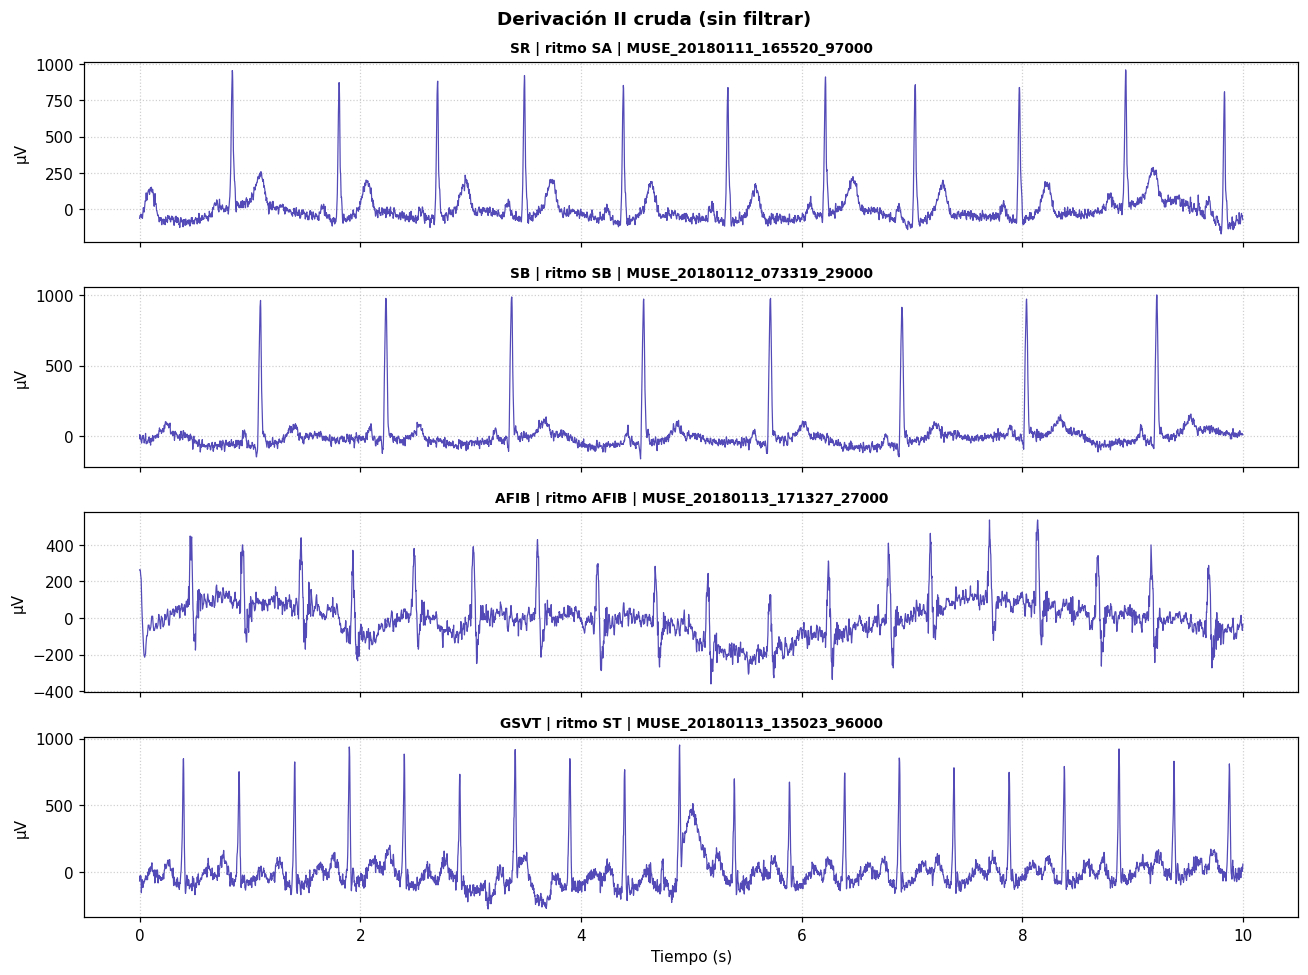

In [67]:
t = np.arange(X_II.shape[1]) / FS
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, g in zip(axes, ['SR', 'SB', 'AFIB', 'GSVT']):
    i = df_sel.index[df_sel['Grupo'] == g][0]
    ax.plot(t, X_II[i], lw=0.8, color='#534AB7')
    ax.set_title(f"{g} | ritmo {df_sel.loc[i, 'Estado']} | {df_sel.loc[i, 'Registro']}", fontsize=9, fontweight='bold')
    ax.set_ylabel("µV"); ax.grid(True, ls=':', alpha=0.6)
axes[-1].set_xlabel("Tiempo (s)")
plt.suptitle("Derivación II cruda (sin filtrar)", fontweight='bold')
plt.tight_layout(); plt.show()

## 3.Flujo de filtrado y comparación de señales entre ambos proyectos:

Se programa el flujo de reducción de ruido en tres etapas sucesivas [3] y se valida comparando el resultado con la misma señal ya filtrada que se usó en el proyecto 1 (`ECGDataDenoised`).

| Etapa | Qué corrige | Parámetros del artículo |
| --- | --- | --- |
| 1. Butterworth pasa-bajas | Ruido de alta frecuencia (> 50 Hz) | Banda de paso 50 Hz, banda de rechazo 60 Hz, rizado ≤ 1 dB, atenuación ≥ 2,5 dB; filtrado hacia adelante y hacia atrás (fase cero) |
| 2. LOESS robusto | Deriva de la línea base | Pesos cero a más de 6 desviaciones absolutas; se resta la tendencia estimada |
| 3. Non-Local Means (NLM) | Ruido residual | Núcleo gaussiano, peso entre fragmentos de señal parecidos (ecuaciones 1 a 3 del artículo) |

In [68]:
from scipy import signal as sps

# ---------------- Configuración del punto 3 ----------------
# Señal ya filtrada del proyecto 1 (solo para validar). Ajusta la ruta si tu carpeta es otra.
CARPETA_DENOISED = os.path.join(CARPETA_BASE, "ECGDataDenoised")
RUTA_FILT = os.path.join(CARPETA_BASE, "derivacionII_filtrada.npy")
RUTA_METR = os.path.join(CARPETA_BASE, "validacion_filtrado.csv")

# Parámetros fijos del NLM
PATCH  = 21      # muestras por fragmento (42 ms)
BUSQ_S = 0.5     # zona de búsqueda: ±0,5 s alrededor de cada muestra
# Parámetros que se calibran en 3.4
SPAN_S = 1.5     # ancho de la ventana del LOESS (s)
LAM_K  = 1.0     # λ del NLM = LAM_K · σ del ruido

assert X_II.shape[0] == len(df_sel), "X_II y df_sel deben tener el mismo número de registros"

# Índice FileName -> ruta de la señal filtrada del proyecto 1
rutas_ref = {os.path.splitext(os.path.basename(p))[0]: p
             for p in glob.glob(os.path.join(CARPETA_DENOISED, "**", "*.csv"), recursive=True)}
print("Señales crudas (X_II):", X_II.shape)
print("Señales filtradas del proyecto 1 encontradas:", len(rutas_ref))

Señales crudas (X_II): (10615, 5000)
Señales filtradas del proyecto 1 encontradas: 10646


## 3.1 Etapa 1: filtro Butterworth pasa-bajas
`buttord` calcula el menor orden que cumple las especificaciones del artículo y `sosfiltfilt` filtra en ambos sentidos, así que la fase queda sin desplazamiento (la fase se anula, y la magnitud del filtro se aplica dos veces).

Orden del filtro: 3 | frecuencia de corte (-3 dB): 61.5 Hz


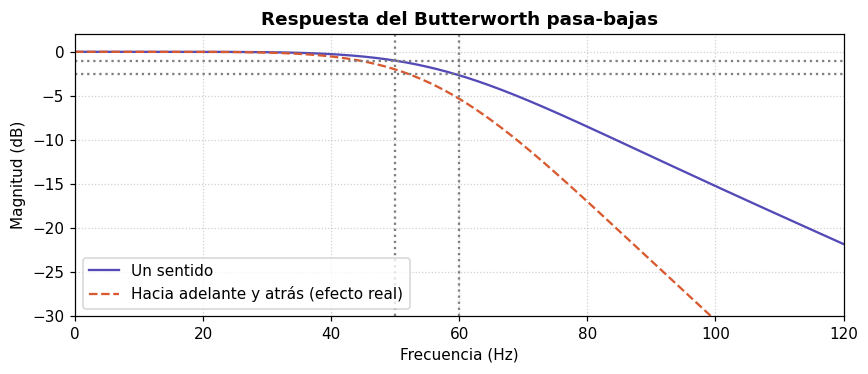

In [69]:
def disenar_butter(fs=FS, fp=50., fst=60., rp=1., rs=2.5):
    orden, wn = sps.buttord(fp, fst, rp, rs, fs=fs)
    sos = sps.butter(orden, wn, btype='low', fs=fs, output='sos')
    return sos, orden, wn

def pasabajas(X, sos):
    return sps.sosfiltfilt(sos, X, axis=-1)

sos, orden, fc = disenar_butter()
print(f"Orden del filtro: {orden} | frecuencia de corte (-3 dB): {fc:.1f} Hz")

f, h = sps.sosfreqz(sos, worN=4096, fs=FS)
plt.figure(figsize=(8, 3.5))
plt.plot(f, 20*np.log10(np.abs(h)), color='#534AB7', label='Un sentido')
plt.plot(f, 40*np.log10(np.abs(h)), color='#D85A30', ls='--', label='Hacia adelante y atrás (efecto real)')
plt.axvline(50, color='gray', ls=':'); plt.axvline(60, color='gray', ls=':')
plt.axhline(-1, color='gray', ls=':'); plt.axhline(-2.5, color='gray', ls=':')
plt.xlim(0, 120); plt.ylim(-30, 2)
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Magnitud (dB)")
plt.title("Respuesta del Butterworth pasa-bajas", fontweight='bold')
plt.legend(); plt.grid(True, ls=':', alpha=0.6); plt.tight_layout(); plt.show()

## 3.2 Etapa 2: LOESS robusto (línea base)
Regresión polinómica local de grado 2 con pesos tricúbicos. Después de cada ajuste, los puntos cuyo residuo supera 6 veces la mediana de los residuos absolutos (MAD) reciben peso cero (pesos bicuadráticos de Cleveland); así los picos QRS no arrastran la tendencia. La tendencia se estima sobre la señal promediada a 50 Hz, porque la línea base es lenta, y se interpola de vuelta a 500 Hz.

In [70]:
def loess_robusto(y, span_s=SPAN_S, fs=FS, decim=10, iter_rob=3):
    """Tendencia LOESS robusta (grado 2). Devuelve un vector del mismo largo que y."""
    n = len(y); m = n // decim
    yd = y[:m*decim].reshape(m, decim).mean(axis=1)
    xd = np.arange(m) * decim + (decim - 1) / 2
    k = min(int(max(5, round(span_s * fs / decim))) | 1, m)      # puntos por ventana
    ini = np.clip(np.arange(m) - k // 2, 0, m - k)
    idx = ini[:, None] + np.arange(k)[None, :]
    xw = xd[idx] - xd[:, None]; yw = yd[idx]
    h = np.abs(xw).max(axis=1, keepdims=True) * 1.0001
    wt = (1 - (np.abs(xw) / h) ** 3) ** 3                          # tricúbico
    rw = np.ones_like(yw)
    for it in range(iter_rob + 1):
        w = wt * rw
        s = [(w * xw**p).sum(1) for p in range(5)]
        t = [(w * yw * xw**p).sum(1) for p in range(3)]
        A = np.stack([np.stack(s[0:3], 1), np.stack(s[1:4], 1), np.stack(s[2:5], 1)], 1) + 1e-12 * np.eye(3)
        beta = np.linalg.solve(A, np.stack(t, 1)[..., None])[..., 0]
        if it == iter_rob:
            break
        res = yw - (beta[:, 0:1] + beta[:, 1:2] * xw + beta[:, 2:3] * xw**2)
        mad = np.median(np.abs(res), axis=1, keepdims=True) + 1e-12
        u = res / (6 * mad)
        rw = np.where(np.abs(u) < 1, (1 - u**2) ** 2, 0.0)         # cero más allá de 6 MAD
    return np.interp(np.arange(n), xd, beta[:, 0])

## 3.3 Etapa 3: Non-Local Means
Cada muestra se reemplaza por un promedio ponderado de las muestras de su entorno, y el peso es mayor cuando el fragmento que rodea a la otra muestra se parece al que rodea a la actual (ecuaciones 1 a 3 del artículo, con núcleo gaussiano). Como los latidos se repiten, el promedio mezcla latidos parecidos y reduce el ruido sin borrar los complejos QRS. λ se toma proporcional a la desviación del ruido de cada registro, que se estima con la mediana de las diferencias sucesivas.

In [71]:
def nlm(X, lam_k=LAM_K, patch=PATCH, busq_s=BUSQ_S, fs=FS):
    """NLM sobre un lote de señales (filas). w(i,j)=exp(-Σ[D(i+δ)-D(j+δ)]² / (2·L·λ²))."""
    X = np.atleast_2d(X).astype(np.float64); B, n = X.shape
    W = int(busq_s * fs)
    dif = np.diff(X, axis=1)
    sigma = np.median(np.abs(dif - np.median(dif, axis=1, keepdims=True)), axis=1) / 0.6745 / np.sqrt(2)
    lam = (lam_k * sigma + 1e-9)[:, None]
    P = np.pad(X, ((0, 0), (W, W)), mode='reflect')
    half = patch // 2
    num = np.zeros_like(X); den = np.zeros_like(X)
    for s in range(-W, W + 1):                                      # desplazamiento j - i
        Ds = P[:, W + s: W + s + n]
        c = np.cumsum(np.pad((X - Ds) ** 2, ((0, 0), (half + 1, half)), mode='reflect'), axis=1)
        suma_fragmento = c[:, patch: patch + n] - c[:, 0: n]       # Σ_δ [D(i+δ)-D(j+δ)]²
        w = np.exp(-suma_fragmento / (2 * patch * lam ** 2))
        num += w * Ds; den += w
    return num / den

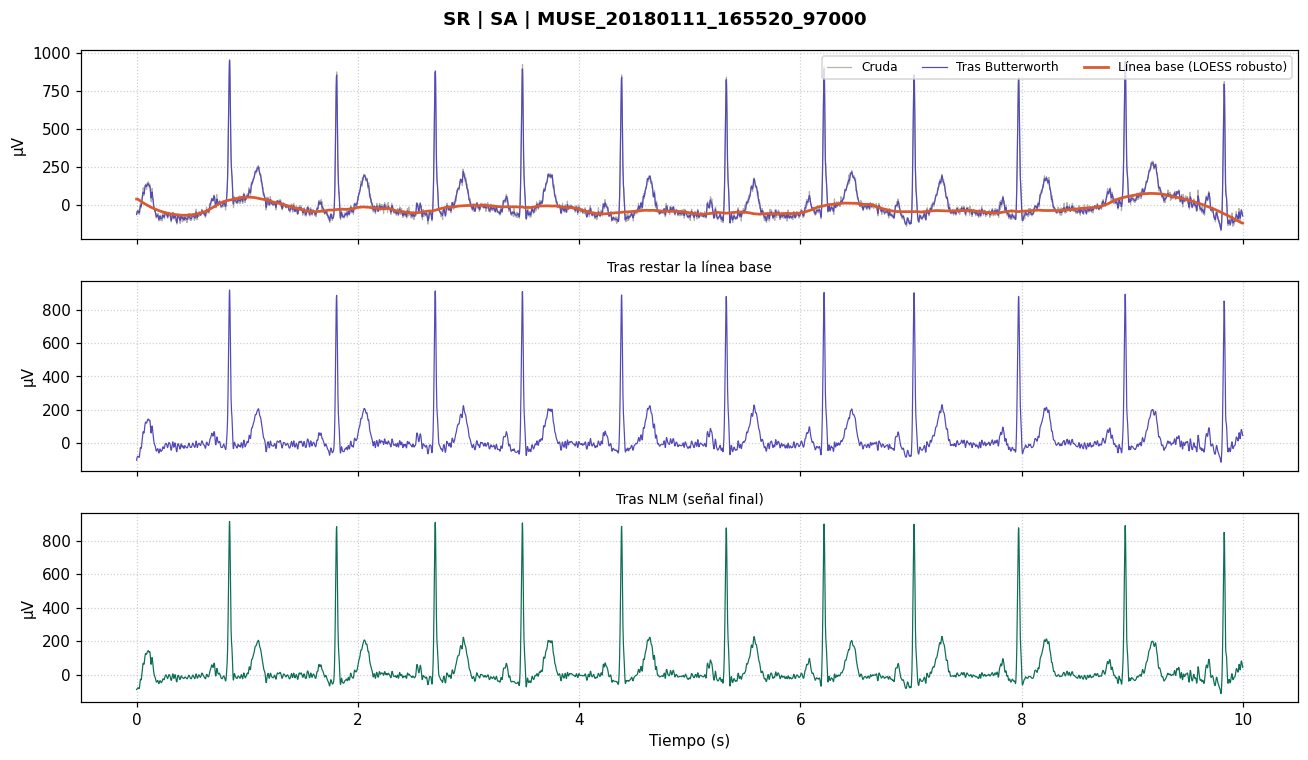

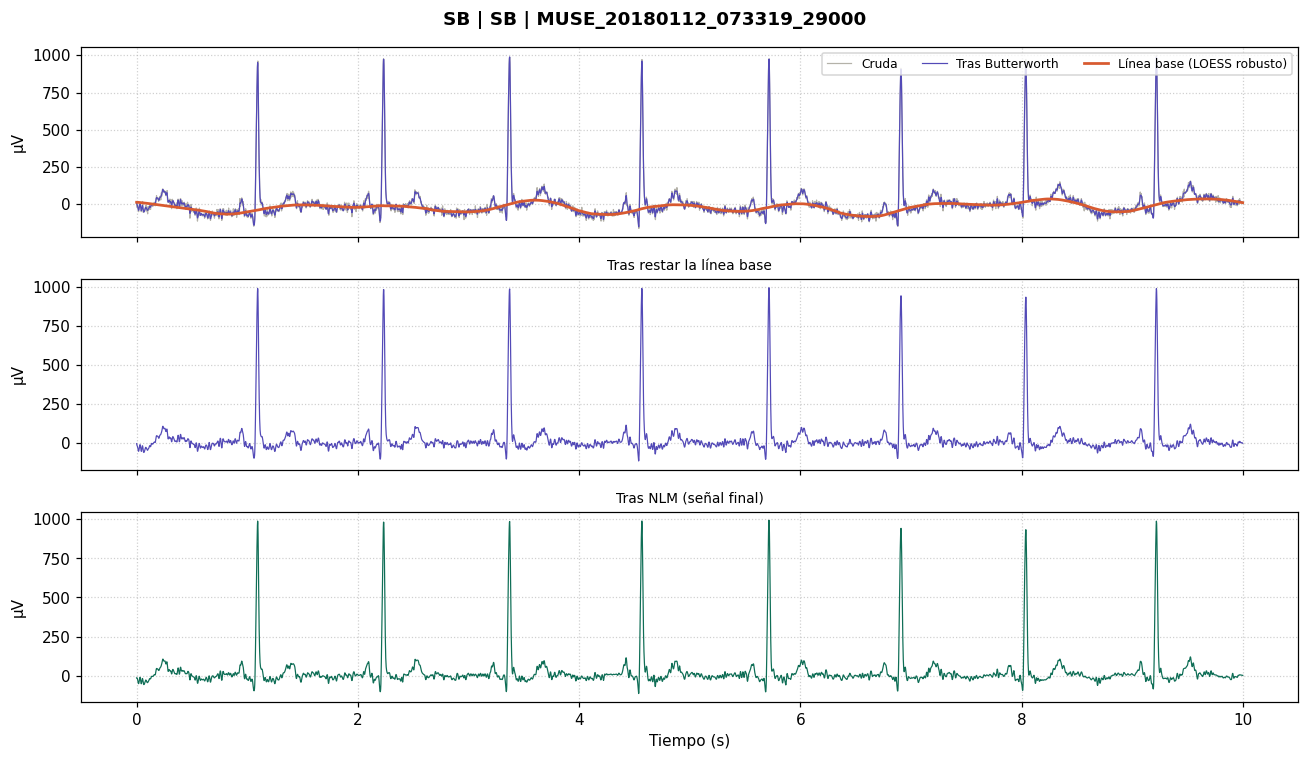

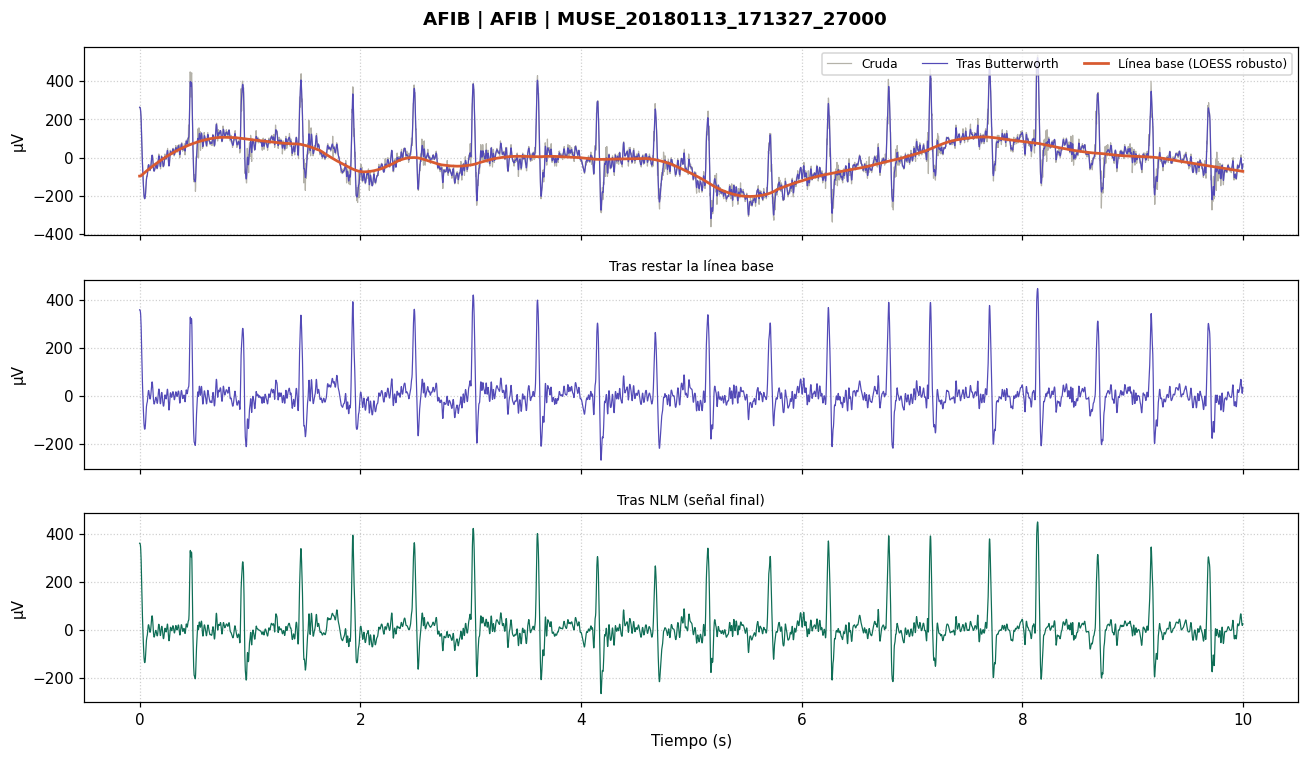

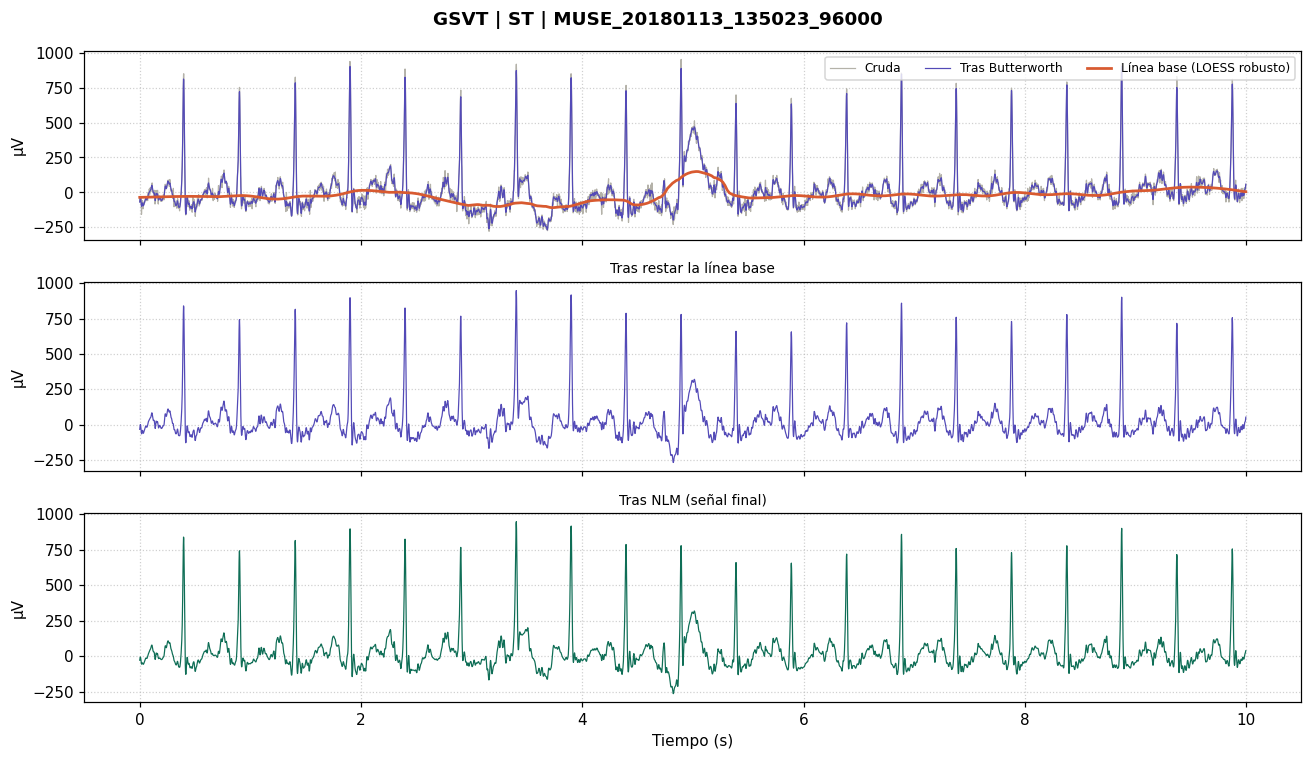

In [72]:
def filtrar_lote(X, sos=sos, span_s=None, lam_k=None):
    """Flujo completo. Devuelve (tras Butterworth, línea base estimada, sin línea base, resultado final)."""
    span_s = SPAN_S if span_s is None else span_s
    lam_k  = LAM_K  if lam_k  is None else lam_k
    X = np.atleast_2d(X).astype(np.float64)
    a = pasabajas(X, sos)
    base = np.vstack([loess_robusto(r, span_s) for r in a])
    b = a - base
    c = nlm(b, lam_k=lam_k)
    return a, base, b, c

# Demostración etapa por etapa en un registro de cada patología
t = np.arange(X_II.shape[1]) / FS
for g in ['SR', 'SB', 'AFIB', 'GSVT']:
    i = df_sel.index[df_sel['Grupo'] == g][0]
    a, base, b, c = filtrar_lote(X_II[i])
    fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    ax[0].plot(t, X_II[i], color='#B4B2A9', lw=0.8, label='Cruda')
    ax[0].plot(t, a[0], color='#534AB7', lw=0.8, label='Tras Butterworth')
    ax[0].plot(t, base[0], color='#D85A30', lw=1.8, label='Línea base (LOESS robusto)')
    ax[1].plot(t, b[0], color='#534AB7', lw=0.8); ax[1].set_title("Tras restar la línea base", fontsize=9)
    ax[2].plot(t, c[0], color='#0F6E56', lw=0.8); ax[2].set_title("Tras NLM (señal final)", fontsize=9)
    ax[0].legend(loc='upper right', fontsize=8, ncol=3)
    for x_ in ax: x_.set_ylabel("µV"); x_.grid(True, ls=':', alpha=0.6)
    ax[-1].set_xlabel("Tiempo (s)")
    fig.suptitle(f"{g} | {df_sel.loc[i, 'Estado']} | {df_sel.loc[i, 'Registro']}", fontweight='bold')
    plt.tight_layout(); plt.show()

## 3.4 Validación contra la señal filtrada del proyecto 1
Para una muestra estratificada se lee la derivación II de `ECGDataDenoised` (la señal del proyecto 1) y se compara con la salida de este flujo. Como el artículo no entrega el ancho del LOESS ni λ, se prueba una rejilla pequeña y se conserva la pareja con menor error mediano. Las comparaciones se hacen restando a cada señal su mediana, para no penalizar un desplazamiento constante.

Medidas por registro:
- **RMSE** (µV): diferencia cuadrática media entre las dos señales.
- **r**: correlación de Pearson.
- **SNR** (dB): 10·log₁₀(varianza de la referencia / varianza de la diferencia).
- **Razón de amplitud**: (máximo − mínimo) de nuestra señal sobre el de la referencia; 1 significa que los picos se conservan.
- **Desfase** (ms): retardo que maximiza la correlación cruzada; debe ser 0 si el filtrado es de fase cero.

In [74]:
def leer_ref(registro):
    return pd.read_csv(rutas_ref[registro], usecols=['II'])['II'].to_numpy(dtype=np.float64)

def metricas(y, ref, fs=FS, max_lag=50):
    y = y - np.median(y); ref = ref - np.median(ref)
    e = y - ref
    r = np.corrcoef(y, ref)[0, 1]
    xc = sps.correlate(y, ref, mode='full')
    lags = sps.correlation_lags(len(y), len(ref), mode='full')
    sel = np.abs(lags) <= max_lag
    lag_ms = lags[sel][np.argmax(xc[sel])] * 1000 / fs
    return dict(RMSE=np.sqrt(np.mean(e**2)), r=r,
                SNR_dB=10 * np.log10(np.var(ref) / np.var(e)),
                Razon_amplitud=np.ptp(y) / np.ptp(ref), Desfase_ms=lag_ms)

assert len(rutas_ref) > 0, f"No se encontraron CSV en {CARPETA_DENOISED}; revisa CARPETA_DENOISED."

# Muestra estratificada: N_POR_GRUPO registros de cada patología
N_POR_GRUPO = 25
rng = np.random.default_rng(0)
idx_val = np.concatenate([rng.choice(df_sel.index[(df_sel['Grupo'] == g) & df_sel['Registro'].isin(rutas_ref)], min(N_POR_GRUPO, ((df_sel['Grupo'] == g) & df_sel['Registro'].isin(rutas_ref)).sum()), replace=False)
                          for g in ['SB', 'SR', 'AFIB', 'GSVT']])
REF = {i: leer_ref(df_sel.loc[i, 'Registro']) for i in idx_val}
print("Registros de validación:", len(idx_val))

# Calibración de SPAN_S y LAM_K (rejilla pequeña, 40 registros)
idx_cal = rng.choice(idx_val, min(40, len(idx_val)), replace=False)
filas = []
for sp in [0.75, 1.0, 1.5, 2.0, 3.0]:
    for lk in [0.7, 1.0, 1.5]:
        _, _, _, c = filtrar_lote(X_II[idx_cal], span_s=sp, lam_k=lk)
        m = [metricas(c[j], REF[i])['RMSE'] for j, i in enumerate(idx_cal)]
        filas.append(dict(SPAN_S=sp, LAM_K=lk, RMSE_mediano=np.median(m)))
cal = pd.DataFrame(filas).sort_values('RMSE_mediano').reset_index(drop=True)
display(cal.head(8))
SPAN_S, LAM_K = cal.loc[0, 'SPAN_S'], cal.loc[0, 'LAM_K']
print(f"Parámetros elegidos: SPAN_S = {SPAN_S} s, LAM_K = {LAM_K}")

ValueError: Usecols do not match columns, columns expected but not found: ['II']

## 4. Analisis de caracteristicas

## 5. 6. Arquitecturas de red, matrices de confusión y red neuronal para la clasificación de las cuatro patologias cardiacas

In [44]:
RUTA_RESULTADOS = "resultados_punto6.csv"      # CSV donde se guarda y se retoma el progreso
df_diag = pd.read_excel(RUTA_DIAGNOSTICOS)     # tabla de diagnósticos completa

if os.path.exists(RUTA_RESULTADOS):
    os.remove(RUTA_RESULTADOS)

## 6. Arquitecturas de red, matrices de confusión y red neuronal para la clasificación de dos de las cuatro patologias cardiacas

## 7. Clasificación con XGBoost

## 8. Funcionamiento del algoritmo de K-means y de las Máquinas de Soporte Vectorial (SVM)

## 9. Análisis de resultados y conclusiones

### 9.1 Equipos comerciales con algoritmos de ayuda diagnostica a partir de señales EKG

### 9.2 Analisis de resultados

### 9.3 Conclusiones

1. 
2. 
3. 
4. 
5. 
6. 
7. 
8. 
9. 




## 10. Bibliografía

[1] J. Zheng et al., “A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients,” figshare, 2019. [Online]. Available: https://doi.org/10.6084/m9.figshare.c.4560497.v2

[2] L.-R. Liu et al., “An arrhythmia classification approach via deep learning using single-lead ECG without QRS wave detection,” Heliyon, vol. 10, Art. no. e27200, Feb. 2024, doi: 10.1016/j.heliyon.2024.e27200.

[3] J. Zheng, J. Zhang, S. Danioko, H. Yao, H. Guo, and C. Rakovski, “A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients,” Sci. Data, vol. 7, no. 1, Art. no. 48, Feb. 2020, doi: 10.1038/s41597-020-0386-x..